# Multivariate Linear Regression

## Part 1: Dataset Loading and Preprocessing
### 1.2 Multivariate Dataset
Dataset: California Housing. Target: median_house_value (in $100,000).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

d = pd.read_csv('https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv')
print(d.head())
d.info()

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639

In [2]:
print(d.isnull().sum())
d['total_bedrooms'] = d['total_bedrooms'].fillna(d['total_bedrooms'].median())
print(d.isnull().sum().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64
0


In [3]:
X = d[['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income']].values
y = d['median_house_value'].values / 100000

In [4]:
np.random.seed(42)
i = np.random.permutation(len(X))
n = int(0.8 * len(X))
X1, y1 = X[i[:n]], y[i[:n]]
X2, y2 = X[i[n:]], y[i[n:]]

u, s = X1.mean(axis=0), X1.std(axis=0)
X1 = np.c_[np.ones(len(X1)), (X1 - u) / s]
X2 = np.c_[np.ones(len(X2)), (X2 - u) / s]

print(X1[:3].round(2))
print(X1.shape, X2.shape)

[[ 1.    0.28  0.2  -0.29 -0.52 -0.24 -0.03 -0.37 -1.15]
 [ 1.    0.05 -0.23  0.11  0.14 -0.24  0.13  0.23 -0.71]
 [ 1.   -1.44  1.02  1.85  0.55 -0.24 -0.1   1.22 -0.21]]
(16512, 9) (4128, 9)


## Part 2: Implementing Linear Regression from Scratch
### 2.1 Hypothesis Function
ŷ = θ₀ + θ₁x₁ + θ₂x₂ + ... + θₙxₙ

In [5]:
def h(t, X):
    return X @ t

### 2.2 Cost Function
J(θ) = (1/n) Σ (y − ŷ)²

In [6]:
def J(t, X, y):
    return np.mean((y - h(t, X)) ** 2)

### 2.3 Gradient Descent
θⱼ := θⱼ − α ∂J/∂θⱼ

Learning rate: 0.1. The features are scaled, so this rate is stable and converges without overshooting.

In [7]:
def gd(X, y, a, k):
    t = np.zeros(X.shape[1])
    H = []
    for _ in range(k):
        t = t - a * (2 / len(y)) * (X.T @ (h(t, X) - y))
        H.append(J(t, X, y))
    return t, H

## Part 3: Optimal Parameters and Visualization
### 3.1 Training and Optimal Parameters

In [8]:
a, k = 0.1, 2000
t, H = gd(X1, y1, a, k)

print('theta =', t)
print('Final MSE =', H[-1])
print('Iterations =', k)
print('First MSE =', H[0])

theta = [ 2.06773381 -0.85613246 -0.91472142  0.14297052 -0.12268754  0.28913289
 -0.49409976  0.37346235  0.74989205]
Final MSE = 0.47461532541106016
Iterations = 2000
First MSE = 3.809358859900666


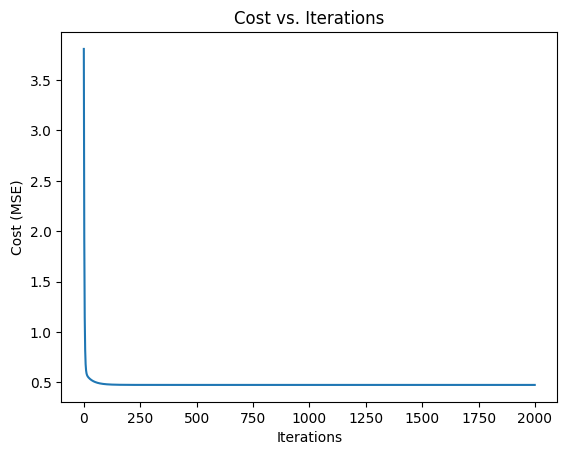

In [9]:
plt.plot(range(len(H)), H)
plt.xlabel("Iterations")
plt.ylabel("Cost (MSE)")
plt.title("Cost vs. Iterations")
plt.show()

### 3.2 Visualization

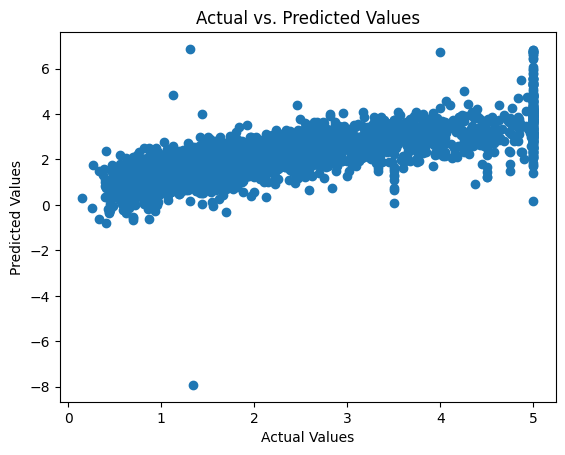

In [10]:
p = h(t, X2)

plt.scatter(y2, p)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs. Predicted Values")
plt.show()

## Part 4: Theory Questions

**Q1. How does the hypothesis function of Multivariate Linear Regression differ from that of Univariate Linear Regression? Explain the role of the parameters associated with multiple features.**

The univariate hypothesis ŷ = mx + c uses one feature and fits a line. The multivariate hypothesis ŷ = θ₀ + θ₁x₁ + ... + θₙxₙ uses many features and fits a hyperplane. Each parameter θⱼ is the weight of feature xⱼ: it shows how much the prediction changes when that feature increases by one unit while the others stay fixed. θ₀ is the intercept.

**Q2. Why can feature scaling be important before applying Gradient Descent in Multivariate Linear Regression? Explain how features with very different scales can affect parameter updates and convergence.**

The gradient of each parameter depends on the values of its feature, so a feature with large values gives large updates and a feature with small values gives tiny ones. With one learning rate, the rate must be small to keep the large-scale parameters from diverging, which makes the other parameters converge very slowly. Scaling puts all features on similar ranges, so all parameters update at a similar speed and convergence is faster and more stable.